# 07 Climate vulnerability and resilience

**Questions**
1. Which African countries are most vulnerable to climate change?
2. Which have the strongest readiness to adapt?
3. Does economic development go with greater resilience?

**What I expect going in**
- **H1** Vulnerability is highest in the Sahel and Central Africa.
- **H2** Richer countries are less vulnerable, and the link holds for climate exposure as well as for adaptive capacity.

**Read before interpreting:** ND-GAIN vulnerability is built from exposure, sensitivity and adaptive capacity, and readiness has an economic component. Adaptive capacity and economic readiness are partly income measures, so "richer countries are more resilient" is partly true by construction. Exposure has no income input, so H2 is tested on exposure separately. Projected exposure barely changes from year to year, so trends mostly reflect sensitivity, capacity and readiness.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.dpi": 110, "font.size": 9})
BLUE, GREY, RED, GREEN = "#1f4e79", "#7f7f7f", "#c00000", "#2f6f4f"

DATA = Path("data")
OUT = Path("outputs") / "07 vulnerability"
OUT.mkdir(parents=True, exist_ok=True)
for f in OUT.glob("*"):
    f.unlink()          # start each run with an empty outputs folder

obs = pd.read_csv(DATA / "observations.csv", dtype={"flag": str})        # long: iso3, year, indicator_id, value, source, flag
panel = pd.read_csv(DATA / "panel.csv")                # wide: one row per country-year
ind = pd.read_csv(DATA / "indicators.csv").set_index("indicator_id")
cty = pd.read_csv(DATA / "countries.csv").set_index("iso3")
AFRICA = cty.index[cty["group"] == "Africa"].tolist()
name = cty["country_name"].to_dict()
af = obs[obs["iso3"].isin(AFRICA)]
afp = panel[panel["iso3"].isin(AFRICA)]


def label(i):
    return f"{ind.at[i, 'indicator_name']} ({ind.at[i, 'unit']})" if i in ind.index else i


def has(*ids):
    missing = [i for i in ids if i not in panel.columns]
    if missing:
        print("Not in the data, skipped:", ", ".join(missing))
    return not missing


def latest(i, frame=None, max_age=5):
    """Latest observed value per country. Values more than max_age years older than the
    newest year for that indicator are dropped so stale points do not enter rankings."""
    s = (frame if frame is not None else af)
    s = s[s["indicator_id"] == i].sort_values("year").groupby("iso3").tail(1)
    s = s[s["year"] >= s["year"].max() - max_age]
    return s.assign(country=s["iso3"].map(name)).sort_values("value", ascending=False)[["iso3", "country", "year", "value"]]


def change(i, base=(2000, 2002)):
    """Change from the 2000 to 2002 average (damps single-year noise) to the latest value.
    Percentage change only where the base is above the 10th percentile, so tiny bases
    do not produce meaningless growth rates."""
    s = af[af["indicator_id"] == i]
    b = s[s["year"].between(*base)].groupby("iso3")["value"].mean().rename("base")
    l = s.sort_values("year").groupby("iso3").tail(1).set_index("iso3")[["year", "value"]].rename(columns={"value": "latest", "year": "latest_year"})
    d = l.join(b, how="inner")
    d["abs_change"] = d["latest"] - d["base"]
    floor = d["base"].abs().quantile(0.10)
    d["pct_change"] = np.where(d["base"].abs() > floor, 100 * d["abs_change"] / d["base"].abs(), np.nan)
    d.insert(0, "country", d.index.map(name))
    return d.sort_values("abs_change", ascending=False)


def median_path(i, iso=None):
    """Africa median by year (only years where at least 10 countries report), or one economy's series."""
    if iso:
        s = obs[(obs["indicator_id"] == i) & (obs["iso3"] == iso)]
        return s.set_index("year")["value"].sort_index()
    s = af[af["indicator_id"] == i].groupby("year")["value"].agg(["median", "count"])
    return s.loc[s["count"] >= 10, "median"]


def barh(df, value, title, xlabel, path, n=15, color=BLUE):
    d = df.head(n).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(d) + 1))
    ax.barh(d["country"], d[value], color=color)
    for y, (v, yr) in enumerate(zip(d[value], d.get("year", d.get("latest_year", [""] * len(d))))):
        ax.text(v, y, f" {v:,.2f} ({yr})" if yr != "" else f" {v:,.2f}", va="center", fontsize=7)
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel); ax.grid(axis="y", visible=False)
    fig.tight_layout(); fig.savefig(OUT / path, dpi=150); plt.show()


def save_excel(path, sheets):
    """Tables to Excel in house style: Tahoma 8, bold headers without fill, frozen header, no gridlines."""
    from openpyxl.styles import Font
    with pd.ExcelWriter(OUT / path, engine="openpyxl") as xl:
        for sheet, frame in sheets.items():
            frame.to_excel(xl, sheet_name=sheet[:31])
        for ws in xl.book.worksheets:
            ws.sheet_view.showGridLines = False
            ws.freeze_panes = "B2"
            for row in ws.iter_rows():
                for c in row:
                    c.font = Font(name="Tahoma", size=8, bold=(c.row == 1))
                    if isinstance(c.value, float):
                        c.number_format = "#,##0.00;(#,##0.00);-"
    return sorted(p.name for p in OUT.iterdir())

## 1. Most vulnerable and most ready (H1)

,iso3,country,year,value,au_region
94779,MRT,Mauritania,2024,0.655,North
95079,SOM,Somalia,2024,0.638,East
95199,TCD,Chad,2024,0.638,Central
94989,SDN,Sudan,2024,0.629,East
94209,ERI,Eritrea,2024,0.629,East
94419,GNB,Guinea-Bissau,2024,0.622,West
93699,BDI,Burundi,2024,0.610,Central
94959,RWA,Rwanda,2024,0.610,East
95049,SLE,Sierra Leone,2024,0.602,West
94119,DJI,Djibouti,2024,0.598,East


,iso3,country,year,value
96609,MUS,Mauritius,2024,0.478
96759,RWA,Rwanda,2024,0.422
96459,MAR,Morocco,2024,0.403
96969,SYC,Seychelles,2024,0.402
95619,BWA,Botswana,2024,0.384
95859,CPV,Cabo Verde,2024,0.381
95949,DZA,Algeria,2024,0.378
95979,EGY,Egypt,2024,0.377
96819,SEN,Senegal,2024,0.376
95529,BEN,Benin,2024,0.372


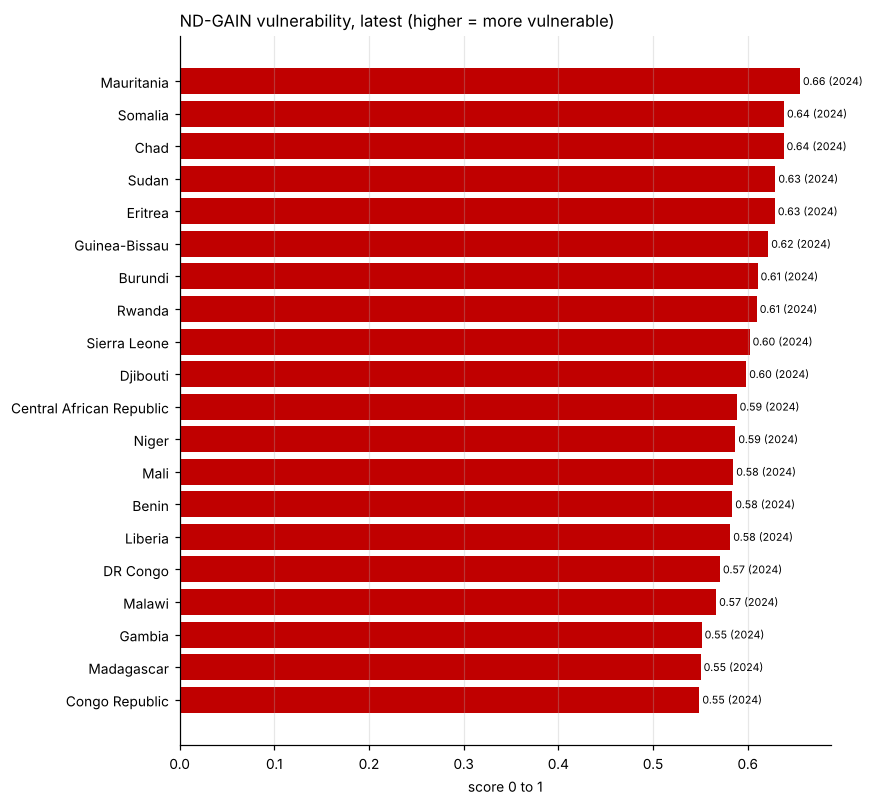

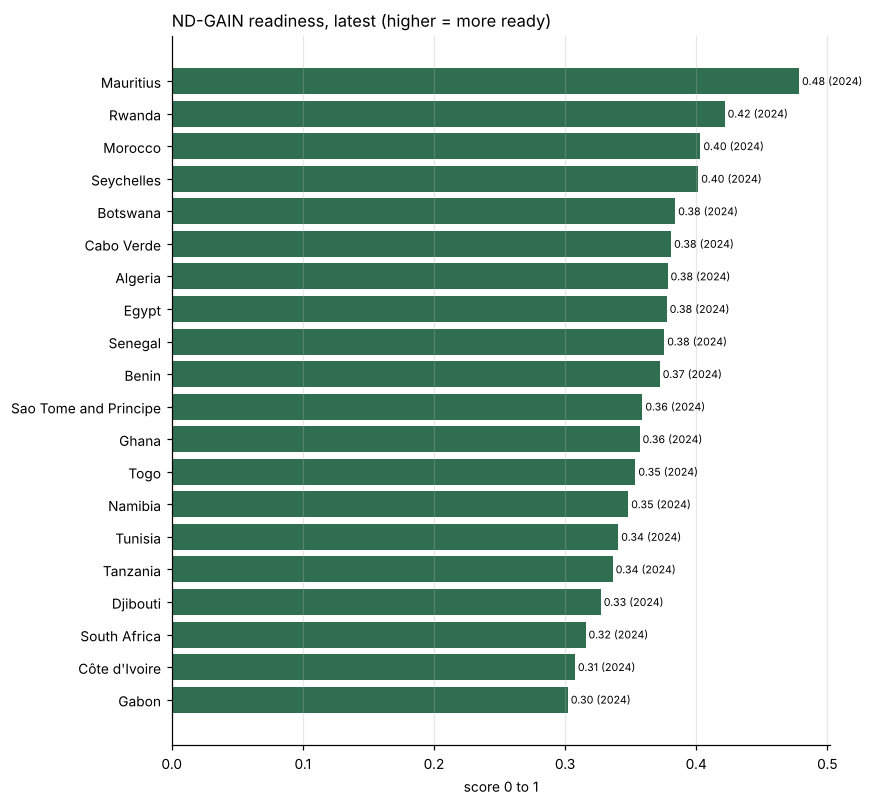

Median vulnerability by AU region:


au_region
Central    0.549
East       0.536
West       0.529
Southern   0.509
North      0.459
Name: value, dtype: float64

In [2]:
vul, rdy = latest("F02"), latest("F03")
vul["au_region"] = vul["iso3"].map(cty["au_region"])
display(vul.head(10)); display(rdy.head(10))
barh(vul, "value", "ND-GAIN vulnerability, latest (higher = more vulnerable)", "score 0 to 1", "vulnerability ranking.png", n=20, color=RED)
barh(rdy, "value", "ND-GAIN readiness, latest (higher = more ready)", "score 0 to 1", "readiness ranking.png", n=20, color=GREEN)
print("Median vulnerability by AU region:")
vul.groupby("au_region")["value"].median().sort_values(ascending=False)

**H1 partly supported: vulnerability is highest in the Sahel and Horn of Africa, with Central Africa highest as a region.**

- Most vulnerable (2024): Mauritania (0.655), Somalia, Chad (0.638 each), Sudan, Eritrea (0.629 each) and Guinea-Bissau (0.622).
- By region, the Central median (0.549) is highest and North (0.459) lowest.
- Most ready: Mauritius (0.478), Rwanda (0.422), Morocco, Seychelles and Botswana.

## 2. The ND-GAIN matrix: vulnerability against readiness

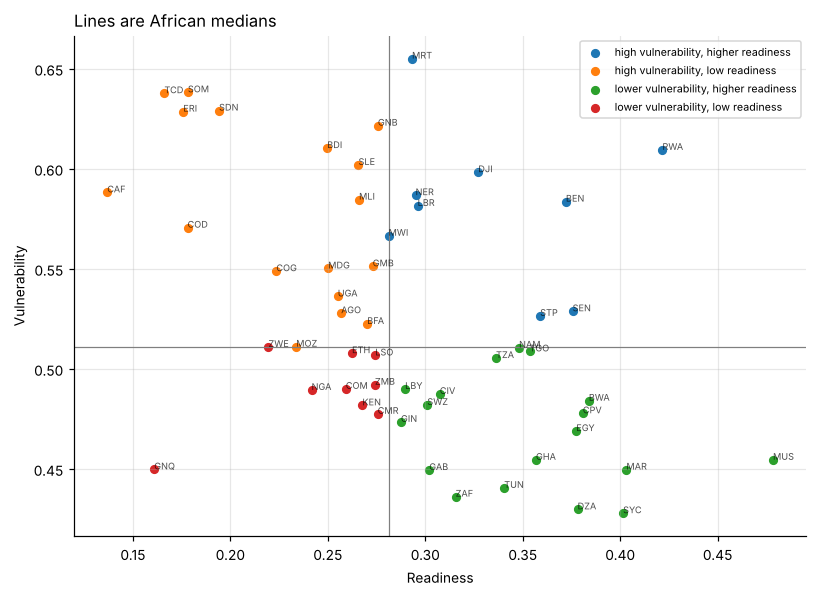

quadrant
lower vulnerability, higher readiness    18
high vulnerability, low readiness        17
high vulnerability, higher readiness      9
lower vulnerability, low readiness        9


In [3]:
if has("F02", "F03"):
    m = pd.DataFrame({"vulnerability": vul.set_index("iso3")["value"], "readiness": rdy.set_index("iso3")["value"]}).dropna()
    vx, ry = m["vulnerability"].median(), m["readiness"].median()
    m["quadrant"] = np.select([(m.vulnerability > vx) & (m.readiness < ry), (m.vulnerability > vx) & (m.readiness >= ry),
                               (m.vulnerability <= vx) & (m.readiness < ry)],
                              ["high vulnerability, low readiness", "high vulnerability, higher readiness", "lower vulnerability, low readiness"],
                              "lower vulnerability, higher readiness")
    fig, ax = plt.subplots(figsize=(7.5, 5.5))
    for q, g in m.groupby("quadrant"):
        ax.scatter(g["readiness"], g["vulnerability"], s=25, label=q)
    for iso, r in m.iterrows():
        ax.annotate(iso, (r["readiness"], r["vulnerability"]), fontsize=6, alpha=0.7)
    ax.axvline(ry, color=GREY, lw=0.8); ax.axhline(vx, color=GREY, lw=0.8)
    ax.set_xlabel("Readiness"); ax.set_ylabel("Vulnerability"); ax.legend(fontsize=7)
    ax.set_title("Lines are African medians", loc="left")
    fig.tight_layout(); fig.savefig(OUT / "ndgain matrix.png", dpi=150); plt.show()
    m["country"] = m.index.map(name)
    print(m["quadrant"].value_counts().to_string())

**17 countries are both highly vulnerable and poorly prepared.**

These are the high-vulnerability, low-readiness group: Chad, Somalia, Eritrea, Sudan, Central African Republic, DR Congo, Burundi, Guinea-Bissau, Sierra Leone, Mali, Madagascar, Congo Republic, Uganda, Angola, Burkina Faso, Gambia and Mozambique. Rwanda, Benin and Senegal are highly vulnerable but comparatively well prepared.

## 3. What drives vulnerability: exposure, sensitivity, capacity

In [4]:
comp = [i for i in ("F04A", "F04B", "F04C") if i in panel]
if comp:
    c = pd.concat({ind.at[i, "indicator_name"].replace("ND-GAIN ", ""): latest(i).set_index("iso3")["value"] for i in comp}, axis=1)
    c.insert(0, "country", c.index.map(name))
    top = vul["iso3"].head(10)
    print("Components for the 10 most vulnerable countries (higher = worse for all three):")
    display(c.loc[c.index.isin(top)])

Components for the 10 most vulnerable countries (higher = worse for all three):


,country,Exposure,Sensitivity,Adaptive capacity
iso3,,,,
BDI,Burundi,0.630,0.439,0.754
SOM,Somalia,0.617,0.537,0.799
RWA,Rwanda,0.612,0.423,0.695
DJI,Djibouti,0.595,0.439,0.723
SDN,Sudan,0.581,0.559,0.738
GNB,Guinea-Bissau,0.568,0.518,0.723
TCD,Chad,0.563,0.477,0.812
ERI,Eritrea,0.552,0.545,0.837
MRT,Mauritania,0.546,0.636,0.795


**Weak adaptive capacity (0.70 to 0.84) is the common thread among the most vulnerable countries, more than exposure or sensitivity.**

## 4. Has vulnerability changed since 2000?

Vulnerability fell in 89% of 53 countries; readiness rose in 40% of 53


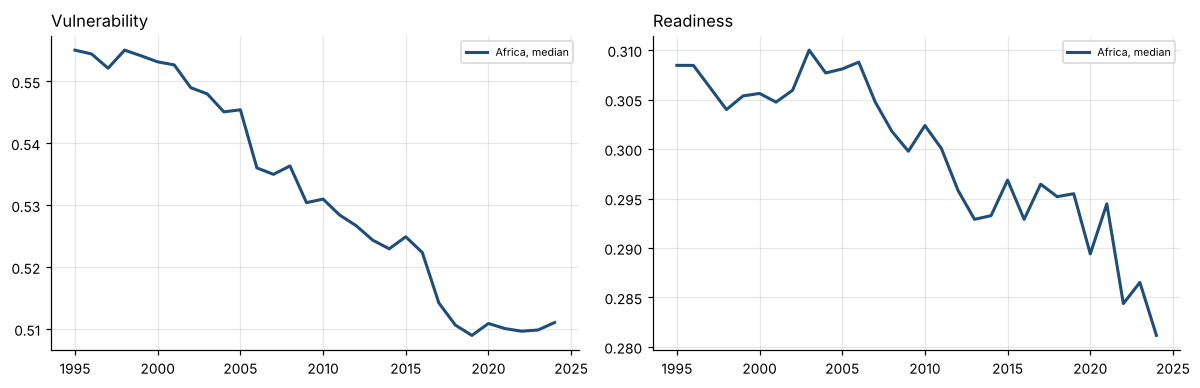

In [5]:
cv, cr = change("F02"), change("F03")
print(f"Vulnerability fell in {(cv['abs_change'] < 0).mean():.0%} of {len(cv)} countries; readiness rose in {(cr['abs_change'] > 0).mean():.0%} of {len(cr)}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, i, t in ((ax[0], "F02", "Vulnerability"), (ax[1], "F03", "Readiness")):
    mpath, w = median_path(i), median_path(i, "WLD")
    a.plot(mpath.index, mpath.values, color=BLUE, lw=2, label="Africa, median")
    if len(w):
        a.plot(w.index, w.values, "--", color=GREY, label="World")
    a.set_title(t, loc="left"); a.legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUT / "vulnerability readiness trend.png", dpi=150); plt.show()

**Vulnerability fell in 89% of countries, but readiness rose in only 40%.**

The African median vulnerability eased from 0.553 to 0.511 between 2000 and 2024, while median readiness slipped from 0.306 to 0.281.

## 5. Income and resilience (H2): all of vulnerability versus exposure only

In [6]:
cols = [i for i in ("F02", "F04A", "F04C", "F03") if i in panel]
if "G02" in panel and cols:
    s = afp[afp["year"] >= 2015].groupby("iso3")[["G02"] + cols].mean()
    res = pd.DataFrame([[label(i), *stats.spearmanr(np.log(s["G02"]), s[i], nan_policy="omit"), s[["G02", i]].dropna().shape[0]] for i in cols],
                       columns=["measure", "spearman_rho_with_income", "p", "n"])
    print("If income only correlates with capacity and readiness, not exposure, the vulnerability-income link is mostly mechanical.")
    display(res)

If income only correlates with capacity and readiness, not exposure, the vulnerability-income link is mostly mechanical.


,measure,spearman_rho_with_income,p,n
0,ND-GAIN Vulnerability (score (index 0 to 100; ...,-0.728,0.000,52
1,ND-GAIN Exposure (score (index 0 to 100; compo...,-0.119,0.401,52
2,ND-GAIN Adaptive capacity (score (index 0 to 1...,-0.699,0.000,51
3,ND-GAIN Readiness (score (index 0 to 100; comp...,0.484,0.000,52


**H2 shows the mechanical link: income is strongly tied to vulnerability (rho = -0.73) and to adaptive capacity (rho = -0.70), but not to exposure (rho = -0.12, p = 0.40).**

Richer countries are less vulnerable because they can cope better, not because they face less climate hazard. The between-country regression in 08 confirms this.

## 6. Save tables

In [7]:
save_excel("vulnerability results.xlsx", {"Vulnerability": vul.set_index("iso3"), "Readiness": rdy.set_index("iso3"),
                                          **({"Matrix": m} if "m" in globals() and isinstance(m, pd.DataFrame) else {}),
                                          **({"Components": c} if "c" in globals() else {}), "Vulnerability change": cv, "Readiness change": cr,
                                          **({"Income links": res} if "res" in globals() else {})})

['ndgain matrix.png',
 'readiness ranking.png',
 'vulnerability ranking.png',
 'vulnerability readiness trend.png',
 'vulnerability results.xlsx']

## What I found

- **The most vulnerable countries are in the Sahel, the Horn of Africa and Central Africa:** Mauritania, Somalia, Chad, Sudan and Eritrea.
- **17 countries combine high vulnerability with low readiness.** They are the priority for adaptation finance.
- **Vulnerability has eased but readiness has not:** vulnerability fell in 89% of countries, but readiness rose in only 40% and the median slipped.
- **Development buys resilience, not lower exposure (H2):** income tracks adaptive capacity (rho = -0.70) but not exposure (rho = -0.12).

**Why it matters for finance:** sovereign and sub-sovereign credit analysis can use the ND-GAIN components directly. Exposure is fixed, but readiness is a governance and fiscal variable. The 17 high-vulnerability, low-readiness countries are where climate shocks are most likely to turn into fiscal and debt stress.